# Rotation registration with a sign-only template

Same setting as `rotation_registration.ipynb`, with one access restriction: the registration algorithm sees only the **sign** of the original image (encoded as a 0/1 black/white field). The rotated observation still has full grayscale values, plus optional additive Gaussian noise.

A second arm asks whether the optimizer invents structure. For each trial, the same observation is also registered against a **fresh random** 0/1 field that did not generate the observation. If bit accuracy on that random field rises well above 1/2, or if its recovered angle clusters near the true angle, the procedure is finding correspondences that were not planted in the data.

Results are written under `results/rotation_registration_sign_template/`.


## 1. Configuration


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.optimize import minimize_scalar

SEED = 42
IMAGE_SIZE = 64
ANGLE_BOUNDS = (-30.0, 30.0)
NOISE_LEVELS = [0.0, 0.1, 0.25, 0.5, 1.0]
N_TRIALS = 100
COARSE_STEP_DEG = 1.0
ROTATE_ORDER = 1
OUTPUT_DIR = Path("results/rotation_registration_sign_template")
FIGURES_DIR = OUTPUT_DIR / "figures"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"image {IMAGE_SIZE}x{IMAGE_SIZE}, trials/noise={N_TRIALS}, noise={NOISE_LEVELS}")
print(f"output -> {OUTPUT_DIR.resolve()}")


image 64x64, trials/noise=100, noise=[0.0, 0.1, 0.25, 0.5, 1.0]
output -> C:\Users\samco\OneDrive\Desktop\gaussian_rotation\results\rotation_registration_sign_template


## 2. Method

**Generation.** Draw a continuous template \(I\) with i.i.d. standard normal pixels. The true angle \(\theta\) is uniform on \([\theta_{\min},\theta_{\max}]\). The observation is
\[
Y = R_{\theta}(I) + \sigma\varepsilon.
\]
The matched bit field is \(B = \mathbf{1}[I \ge 0]\) (shown as black/white). Exact zeros are grouped with the nonnegative class.

**What the optimizer may use.** Only \(B\) and \(Y\). It never sees the grayscale values of \(I\).

**Objective.** For a candidate angle \(\phi\), warp the observation back by \(-\phi\) with bilinear interpolation,
\[
\tilde Y_{\phi} = R_{-\phi}(Y),
\]
then score agreement with the bit template on the fixed valid mask \(M\):
- continuous correlation: \(\mathrm{corr}(B_{\pm}, \tilde Y_{\phi})\) with \(B_{\pm} = 2B-1 \in \{\pm 1\}\)
- bit accuracy: fraction of sites with \(\mathrm{sign}(\tilde Y_{\phi}) = B_{\pm}\) (zero in \(\tilde Y_{\phi}\) counts as nonnegative)
- bit MSE: mean squared error between \(B_{\pm}\) and \(\mathrm{sign}(\tilde Y_{\phi})\)
- continuous MSE: mean squared error between \(B_{\pm}\) and \(\tilde Y_{\phi}\)

Registration **maximizes the continuous correlation** on a 1° coarse grid, then refines with Brent's method. Bit accuracy is the evaluation metric of interest; correlation is a smooth surrogate that still uses only template signs and observation grayscales.

**Valid mask.** Same construction as the grayscale rotation notebook: intersection of bilinear validity over the full angle search range.

**Random control.** An independent bit field \(B^{\mathrm{rand}}\) is drawn as signs of a fresh Gaussian image. It is registered to the **same** \(Y\) with the same optimizer. Under a null with no planted geometry, bit accuracy should stay near \(1/2\) and recovered angles should not concentrate on \(\theta\).


In [2]:
def rotate_image(image: np.ndarray, angle_deg: float) -> np.ndarray:
    return ndimage.rotate(
        image,
        angle=float(angle_deg),
        reshape=False,
        order=ROTATE_ORDER,
        mode="constant",
        cval=0.0,
        prefilter=True,
    )


def validity_mask_for_angle(shape: tuple[int, int], angle_deg: float) -> np.ndarray:
    ones = np.ones(shape, dtype=np.float64)
    return rotate_image(ones, angle_deg) > (1.0 - 1e-3)


def fixed_valid_mask(shape: tuple[int, int], angle_min: float, angle_max: float, step: float = 1.0) -> np.ndarray:
    angles = np.arange(angle_min, angle_max + 0.5 * step, step)
    mask = np.ones(shape, dtype=bool)
    for angle in angles:
        mask &= validity_mask_for_angle(shape, float(angle))
    if not mask.any():
        raise RuntimeError("valid mask is empty")
    return mask


def bits_from_continuous(image: np.ndarray) -> np.ndarray:
    # 0/1 field; exact zero counts as 1 (nonnegative).
    return (np.asarray(image) >= 0).astype(np.float64)


def bits_to_pm(bits01: np.ndarray) -> np.ndarray:
    return 2.0 * bits01 - 1.0


def sign_pm(image: np.ndarray) -> np.ndarray:
    return np.where(np.asarray(image) >= 0, 1.0, -1.0)


def angular_error_deg(estimated: float, truth: float) -> float:
    return float(abs(((estimated - truth + 180.0) % 360.0) - 180.0))


def score_alignment(bits01: np.ndarray, observation: np.ndarray, angle_deg: float, mask: np.ndarray) -> dict:
    warped = rotate_image(observation, -float(angle_deg))
    bits_pm = bits_to_pm(bits01)
    warped_masked = warped[mask]
    bits_masked = bits_pm[mask]
    signed = sign_pm(warped_masked)
    bit_agree = signed == bits_masked
    # Continuous correlation between ±1 bits and grayscale warped observation.
    if bits_masked.size < 2 or np.std(warped_masked) < 1e-12:
        corr = 0.0
    else:
        corr = float(np.corrcoef(bits_masked, warped_masked)[0, 1])
    return {
        "correlation": corr,
        "bit_accuracy": float(np.mean(bit_agree)),
        "bit_mse": float(np.mean((bits_masked - signed) ** 2)),
        "continuous_mse": float(np.mean((bits_masked - warped_masked) ** 2)),
    }


VALID_MASK = fixed_valid_mask((IMAGE_SIZE, IMAGE_SIZE), ANGLE_BOUNDS[0], ANGLE_BOUNDS[1], step=1.0)
print(f"valid pixels: {int(VALID_MASK.sum())} / {IMAGE_SIZE * IMAGE_SIZE} ({100 * VALID_MASK.mean():.1f}%)")


valid pixels: 3124 / 4096 (76.3%)


In [3]:
def coarse_search(bits01: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> tuple[float, np.ndarray, np.ndarray]:
    lo, hi = ANGLE_BOUNDS
    candidates = np.arange(lo, hi + 0.5 * COARSE_STEP_DEG, COARSE_STEP_DEG)
    values = np.empty(candidates.shape, dtype=np.float64)
    for i, angle in enumerate(candidates):
        values[i] = score_alignment(bits01, observation, float(angle), mask)["correlation"]
    best = float(candidates[int(np.argmax(values))])
    return best, candidates, values


def refine_angle(bits01: np.ndarray, observation: np.ndarray, mask: np.ndarray, coarse_angle: float) -> float:
    lo, hi = ANGLE_BOUNDS
    bracket_lo = max(lo, coarse_angle - COARSE_STEP_DEG)
    bracket_hi = min(hi, coarse_angle + COARSE_STEP_DEG)
    if bracket_hi <= bracket_lo:
        return float(np.clip(coarse_angle, lo, hi))

    def objective(angle: float) -> float:
        # minimize negative correlation
        return -score_alignment(bits01, observation, float(angle), mask)["correlation"]

    result = minimize_scalar(objective, bounds=(bracket_lo, bracket_hi), method="bounded", options={"xatol": 1e-4})
    if not result.success:
        return float(coarse_angle)
    return float(result.x)


def register_sign_template(bits01: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> dict:
    started = time.perf_counter()
    coarse_angle, candidates, values = coarse_search(bits01, observation, mask)
    estimated = refine_angle(bits01, observation, mask, coarse_angle)
    metrics = score_alignment(bits01, observation, estimated, mask)
    elapsed = time.perf_counter() - started
    return {
        "estimated_angle": estimated,
        "coarse_angle": coarse_angle,
        "candidates": candidates,
        "correlation_curve": values,
        "runtime_s": elapsed,
        **metrics,
    }


def make_trial(rng: np.random.Generator, size: int, noise_std: float, mask: np.ndarray) -> dict:
    template = rng.standard_normal((size, size)).astype(np.float64)
    matched_bits = bits_from_continuous(template)
    random_bits = bits_from_continuous(rng.standard_normal((size, size)))
    true_angle = float(rng.uniform(ANGLE_BOUNDS[0], ANGLE_BOUNDS[1]))
    observation = rotate_image(template, true_angle) + noise_std * rng.standard_normal((size, size))

    matched = register_sign_template(matched_bits, observation, mask)
    random = register_sign_template(random_bits, observation, mask)

    # Also score the random field at the matched estimate and at the true angle, and
    # the matched field at the random estimate — useful null diagnostics.
    random_at_true = score_alignment(random_bits, observation, true_angle, mask)
    random_at_matched_est = score_alignment(random_bits, observation, matched["estimated_angle"], mask)
    matched_at_random_est = score_alignment(matched_bits, observation, random["estimated_angle"], mask)

    return {
        "template": template,
        "matched_bits": matched_bits,
        "random_bits": random_bits,
        "observation": observation,
        "true_angle": true_angle,
        "noise_std": noise_std,
        "matched": matched,
        "random": random,
        "random_at_true": random_at_true,
        "random_at_matched_est": random_at_matched_est,
        "matched_at_random_est": matched_at_random_est,
    }


_warmup = make_trial(np.random.default_rng(0), IMAGE_SIZE, 0.25, VALID_MASK)
print(
    f"warm-up matched: est={_warmup['matched']['estimated_angle']:.3f} "
    f"(true {_warmup['true_angle']:.3f}), bit_acc={_warmup['matched']['bit_accuracy']:.3f}, "
    f"runtime={_warmup['matched']['runtime_s']:.3f}s"
)
print(
    f"warm-up random:  est={_warmup['random']['estimated_angle']:.3f}, "
    f"bit_acc={_warmup['random']['bit_accuracy']:.3f}, "
    f"runtime={_warmup['random']['runtime_s']:.3f}s"
)


warm-up matched: est=-1.756 (true -1.660), bit_acc=0.794, runtime=0.013s
warm-up random:  est=14.782, bit_acc=0.504, runtime=0.014s


## 3. Example trial

Left to right: continuous original, matched 0/1 template, random 0/1 control, noisy observation. The correlation curves are the coarse-search objectives for the matched and random templates against the same observation.


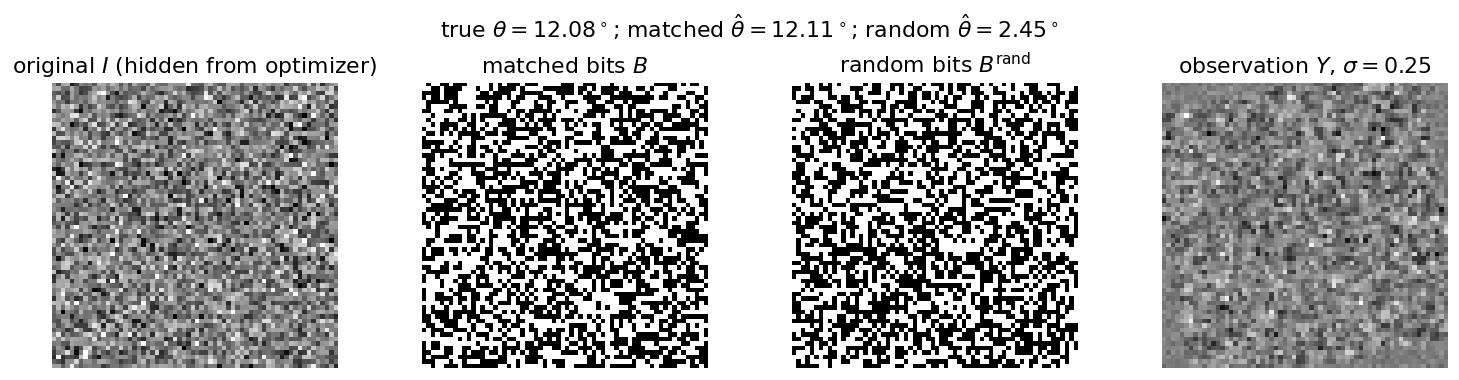

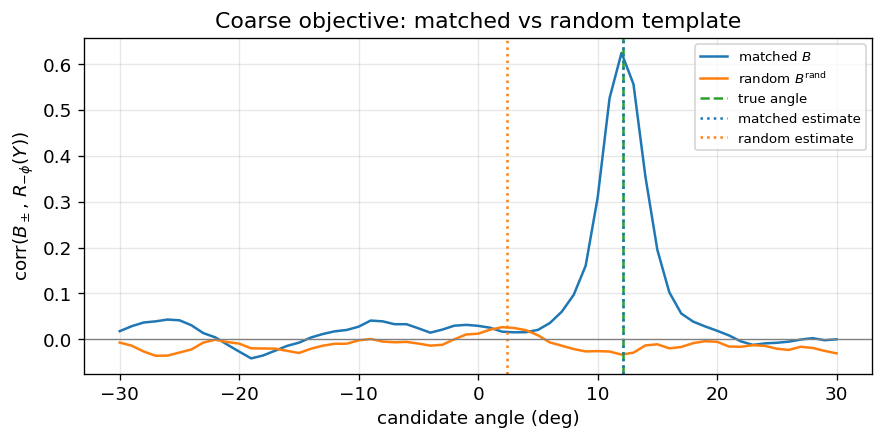

Matched: {'estimated_angle': 12.108672009116326, 'bit_accuracy': 0.7893725992317542, 'correlation': 0.6252998079110569, 'bit_mse': 0.8425096030729834, 'continuous_mse': 0.6141119042513024}
Random:  {'estimated_angle': 2.451152031435582, 'bit_accuracy': 0.5115236875800256, 'correlation': 0.026095612345297815, 'bit_mse': 1.9539052496798976, 'continuous_mse': 1.257420732516136}
Random bits scored at the true angle: {'correlation': -0.0339982483207182, 'bit_accuracy': 0.49903969270166454, 'bit_mse': 2.003841229193342, 'continuous_mse': 1.3495809434100128}


In [4]:
example = make_trial(np.random.default_rng(SEED), IMAGE_SIZE, noise_std=0.25, mask=VALID_MASK)
clean_rotated = rotate_image(example["template"], example["true_angle"])

fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.2))
vmax = np.percentile(np.abs(example["template"]), 99)
axes[0].imshow(example["template"], cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
axes[0].set_title("original $I$ (hidden from optimizer)")
axes[1].imshow(example["matched_bits"], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title("matched bits $B$")
axes[2].imshow(example["random_bits"], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[2].set_title(r"random bits $B^{\mathrm{rand}}$")
axes[3].imshow(example["observation"], cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
axes[3].set_title(fr"observation $Y$, $\sigma={example['noise_std']}$")
for ax in axes:
    ax.axis("off")
fig.suptitle(
    fr"true $\theta={example['true_angle']:.2f}^\circ$; "
    fr"matched $\hat\theta={example['matched']['estimated_angle']:.2f}^\circ$; "
    fr"random $\hat\theta={example['random']['estimated_angle']:.2f}^\circ$"
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_images.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(example["matched"]["candidates"], example["matched"]["correlation_curve"], label="matched $B$")
ax.plot(example["random"]["candidates"], example["random"]["correlation_curve"], label=r"random $B^{\mathrm{rand}}$")
ax.axvline(example["true_angle"], color="C2", ls="--", label="true angle")
ax.axvline(example["matched"]["estimated_angle"], color="C0", ls=":", label="matched estimate")
ax.axvline(example["random"]["estimated_angle"], color="C1", ls=":", label="random estimate")
ax.axhline(0.0, color="0.5", lw=0.8)
ax.set_xlabel("candidate angle (deg)")
ax.set_ylabel(r"corr($B_\pm$, $R_{-\phi}(Y)$)")
ax.set_title("Coarse objective: matched vs random template")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_objective_curves.png", bbox_inches="tight")
plt.show()

print("Matched:", {k: example["matched"][k] for k in ["estimated_angle", "bit_accuracy", "correlation", "bit_mse", "continuous_mse"]})
print("Random: ", {k: example["random"][k] for k in ["estimated_angle", "bit_accuracy", "correlation", "bit_mse", "continuous_mse"]})
print("Random bits scored at the true angle:", example["random_at_true"])


## 4. Full experiment

Matched and random registrations share the same templates, angles, and observations within a trial. Across noise levels, the continuous image and true angle are held fixed; only the observation noise changes.


In [5]:
def run_experiment(n_trials: int, noise_levels: list[float], size: int, seed: int) -> pd.DataFrame:
    mask = fixed_valid_mask((size, size), ANGLE_BOUNDS[0], ANGLE_BOUNDS[1], step=1.0)
    rows = []
    started = time.perf_counter()
    total = n_trials * len(noise_levels)
    done = 0
    for trial in range(n_trials):
        trial_rng = np.random.default_rng(seed + 10_000 * trial + 17)
        template = trial_rng.standard_normal((size, size)).astype(np.float64)
        matched_bits = bits_from_continuous(template)
        random_bits = bits_from_continuous(trial_rng.standard_normal((size, size)))
        true_angle = float(trial_rng.uniform(ANGLE_BOUNDS[0], ANGLE_BOUNDS[1]))
        clean = rotate_image(template, true_angle)
        for noise_std in noise_levels:
            noise_rng = np.random.default_rng(seed + 10_000 * trial + int(1_000_000 * noise_std) + 23)
            observation = clean + noise_std * noise_rng.standard_normal((size, size))
            matched = register_sign_template(matched_bits, observation, mask)
            random = register_sign_template(random_bits, observation, mask)
            random_at_true = score_alignment(random_bits, observation, true_angle, mask)
            rows.append({
                "trial": trial,
                "noise_std": float(noise_std),
                "true_angle": true_angle,
                "matched_estimated_angle": matched["estimated_angle"],
                "matched_angular_error": angular_error_deg(matched["estimated_angle"], true_angle),
                "matched_bit_accuracy": matched["bit_accuracy"],
                "matched_correlation": matched["correlation"],
                "matched_bit_mse": matched["bit_mse"],
                "matched_continuous_mse": matched["continuous_mse"],
                "matched_runtime_s": matched["runtime_s"],
                "random_estimated_angle": random["estimated_angle"],
                "random_angular_error": angular_error_deg(random["estimated_angle"], true_angle),
                "random_bit_accuracy": random["bit_accuracy"],
                "random_correlation": random["correlation"],
                "random_bit_mse": random["bit_mse"],
                "random_continuous_mse": random["continuous_mse"],
                "random_runtime_s": random["runtime_s"],
                "random_bit_accuracy_at_true": random_at_true["bit_accuracy"],
                "random_correlation_at_true": random_at_true["correlation"],
            })
            done += 1
            if done == 1 or done == total or done % max(1, total // 10) == 0:
                elapsed = time.perf_counter() - started
                eta = (total - done) / (done / max(elapsed, 1e-9))
                print(
                    f"[{done}/{total}] trial={trial} sigma={noise_std:g} "
                    f"matched_err={rows[-1]['matched_angular_error']:.3f} "
                    f"matched_bit={rows[-1]['matched_bit_accuracy']:.3f} "
                    f"random_bit={rows[-1]['random_bit_accuracy']:.3f} "
                    f"elapsed={elapsed:.1f}s eta={eta:.1f}s",
                    flush=True,
                )
    return pd.DataFrame(rows)


results = run_experiment(N_TRIALS, NOISE_LEVELS, IMAGE_SIZE, SEED)
results_path = OUTPUT_DIR / "trial_results.csv"
results.to_csv(results_path, index=False)
print(f"wrote {results_path} ({len(results)} rows)")


[1/500] trial=0 sigma=0 matched_err=0.046 matched_bit=0.835 random_bit=0.510 elapsed=0.0s eta=15.3s


[50/500] trial=9 sigma=1 matched_err=0.044 matched_bit=0.673 random_bit=0.516 elapsed=5.7s eta=51.7s


[100/500] trial=19 sigma=1 matched_err=0.068 matched_bit=0.688 random_bit=0.514 elapsed=15.7s eta=62.9s


[150/500] trial=29 sigma=1 matched_err=0.012 matched_bit=0.671 random_bit=0.512 elapsed=26.1s eta=60.8s


[200/500] trial=39 sigma=1 matched_err=0.100 matched_bit=0.680 random_bit=0.506 elapsed=36.3s eta=54.4s


...

[350/500] trial=69 sigma=1 matched_err=0.037 matched_bit=0.690 random_bit=0.508 elapsed=66.9s eta=28.7s


[400/500] trial=79 sigma=1 matched_err=0.005 matched_bit=0.680 random_bit=0.525 elapsed=77.0s eta=19.3s


[450/500] trial=89 sigma=1 matched_err=0.098 matched_bit=0.667 random_bit=0.523 elapsed=87.1s eta=9.7s


[500/500] trial=99 sigma=1 matched_err=0.027 matched_bit=0.688 random_bit=0.504 elapsed=97.5s eta=0.0s


wrote results\rotation_registration_sign_template\trial_results.csv (500 rows)


## 5. Summary: matched template versus random control

Chance bit accuracy is \(1/2\). The random arm is the check for invented correspondences: its bit accuracy at its own optimized angle, and at the true angle, should stay near chance if the optimizer is not manufacturing a geometric story.


In [6]:
summary_rows = []
for noise_std, block in results.groupby("noise_std"):
    summary_rows.append({
        "noise_std": float(noise_std),
        "n": int(len(block)),
        "matched_mean_abs_err_deg": float(block.matched_angular_error.mean()),
        "matched_median_abs_err_deg": float(block.matched_angular_error.median()),
        "matched_std_abs_err_deg": float(block.matched_angular_error.std(ddof=1)),
        "matched_mean_bit_accuracy": float(block.matched_bit_accuracy.mean()),
        "matched_mean_correlation": float(block.matched_correlation.mean()),
        "matched_mean_bit_mse": float(block.matched_bit_mse.mean()),
        "matched_mean_continuous_mse": float(block.matched_continuous_mse.mean()),
        "random_mean_abs_err_deg": float(block.random_angular_error.mean()),
        "random_mean_bit_accuracy": float(block.random_bit_accuracy.mean()),
        "random_mean_correlation": float(block.random_correlation.mean()),
        "random_mean_bit_mse": float(block.random_bit_mse.mean()),
        "random_bit_accuracy_at_true": float(block.random_bit_accuracy_at_true.mean()),
        "random_corr_at_true": float(block.random_correlation_at_true.mean()),
        "matched_mean_runtime_s": float(block.matched_runtime_s.mean()),
    })
summary = pd.DataFrame(summary_rows).sort_values("noise_std").reset_index(drop=True)
summary.to_csv(OUTPUT_DIR / "summary_by_noise.csv", index=False)
print(summary.round(4).to_string(index=False))

zero = summary.loc[np.isclose(summary.noise_std, 0.0)].iloc[0]
print(
    f"\nZero-noise matched: mean |err|={zero.matched_mean_abs_err_deg:.4f} deg, "
    f"bit accuracy={zero.matched_mean_bit_accuracy:.4f}."
)
print(
    f"Zero-noise random control: bit accuracy at its estimate={zero.random_mean_bit_accuracy:.4f}, "
    f"at true angle={zero.random_bit_accuracy_at_true:.4f} (chance=0.5)."
)


 noise_std   n  matched_mean_abs_err_deg  matched_median_abs_err_deg  matched_std_abs_err_deg  matched_mean_bit_accuracy  matched_mean_correlation  matched_mean_bit_mse  matched_mean_continuous_mse  random_mean_abs_err_deg  random_mean_bit_accuracy  random_mean_correlation  random_mean_bit_mse  random_bit_accuracy_at_true  random_corr_at_true  matched_mean_runtime_s
      0.00 100                    0.0388                      0.0335                   0.0292                     0.8255                    0.6671                0.6981                       0.5731                  20.5707                    0.5136                   0.0348               1.9457                       0.4997              -0.0001                  0.0920
      0.10 100                    0.0392                      0.0312                   0.0283                     0.8206                    0.6619                0.7175                       0.5777                  20.3537                    0.5139              

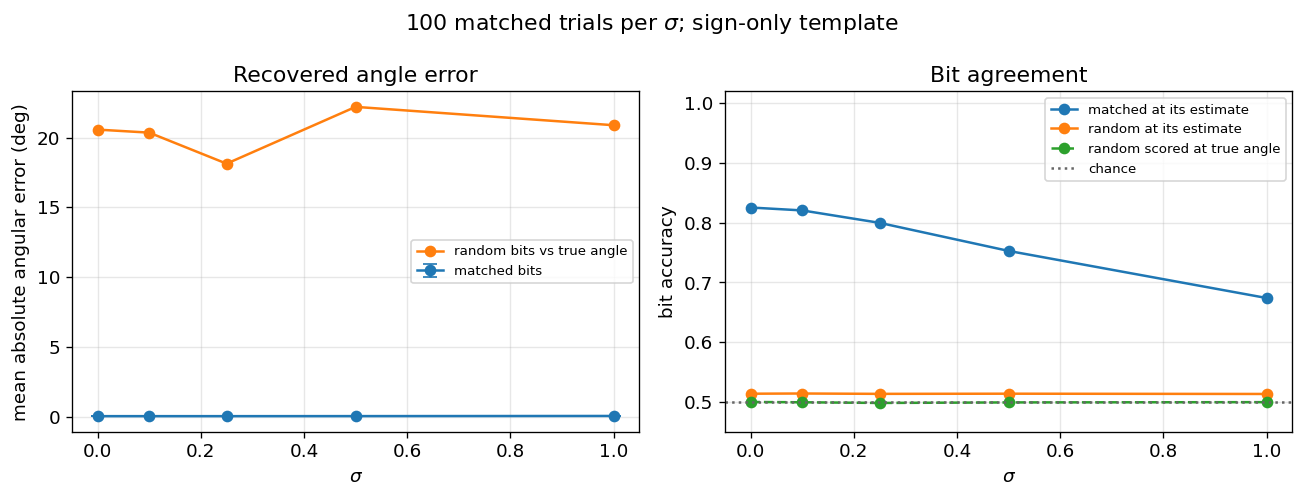

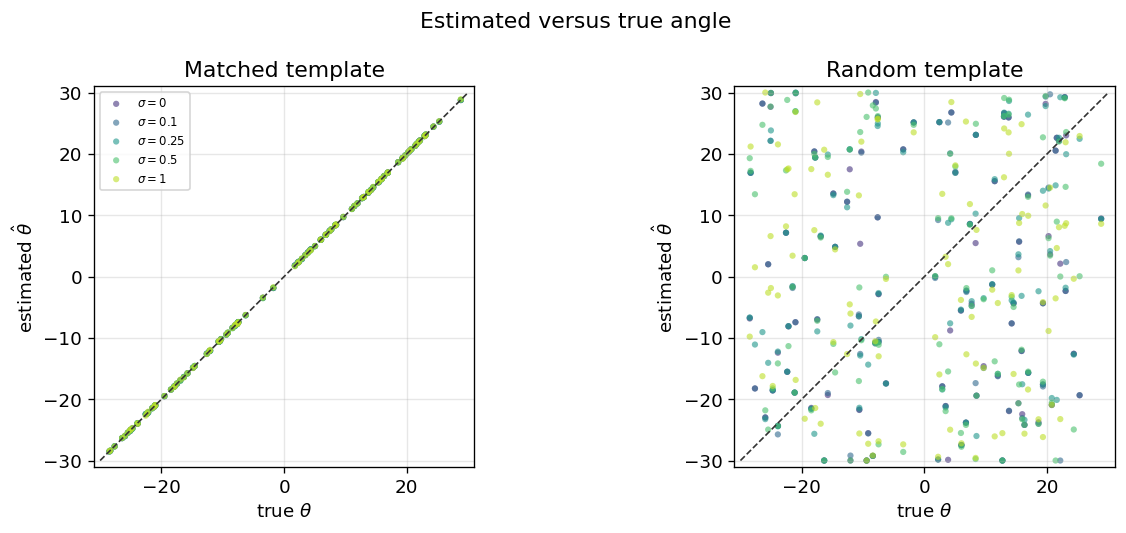

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].errorbar(
    summary.noise_std,
    summary.matched_mean_abs_err_deg,
    yerr=summary.matched_std_abs_err_deg / np.sqrt(summary.n),
    fmt="-o",
    label="matched bits",
    capsize=4,
)
axes[0].plot(summary.noise_std, summary.random_mean_abs_err_deg, "-o", label="random bits vs true angle")
axes[0].set_xlabel(r"$\sigma$")
axes[0].set_ylabel("mean absolute angular error (deg)")
axes[0].set_title("Recovered angle error")
axes[0].legend(fontsize=8)

axes[1].plot(summary.noise_std, summary.matched_mean_bit_accuracy, "-o", label="matched at its estimate")
axes[1].plot(summary.noise_std, summary.random_mean_bit_accuracy, "-o", label="random at its estimate")
axes[1].plot(summary.noise_std, summary.random_bit_accuracy_at_true, "--o", label="random scored at true angle")
axes[1].axhline(0.5, color="0.4", ls=":", label="chance")
axes[1].set_xlabel(r"$\sigma$")
axes[1].set_ylabel("bit accuracy")
axes[1].set_title("Bit agreement")
axes[1].set_ylim(0.45, 1.02)
axes[1].legend(fontsize=8)
fig.suptitle(fr"{N_TRIALS} matched trials per $\sigma$; sign-only template")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "error_and_bits_vs_noise.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for noise_std, color in zip(NOISE_LEVELS, plt.cm.viridis(np.linspace(0.15, 0.9, len(NOISE_LEVELS)))):
    block = results.loc[np.isclose(results.noise_std, noise_std)]
    axes[0].scatter(
        block.true_angle,
        block.matched_estimated_angle,
        s=14,
        alpha=0.6,
        color=color,
        edgecolors="none",
        label=fr"$\sigma={noise_std:g}$",
    )
    axes[1].scatter(
        block.true_angle,
        block.random_estimated_angle,
        s=14,
        alpha=0.6,
        color=color,
        edgecolors="none",
        label=fr"$\sigma={noise_std:g}$",
    )
for ax, title in zip(axes, ["Matched template", "Random template"]):
    ax.plot(ANGLE_BOUNDS, ANGLE_BOUNDS, color="0.2", ls="--", lw=1)
    ax.set_xlim(ANGLE_BOUNDS[0] - 1, ANGLE_BOUNDS[1] + 1)
    ax.set_ylim(ANGLE_BOUNDS[0] - 1, ANGLE_BOUNDS[1] + 1)
    ax.set_aspect("equal")
    ax.set_xlabel(r"true $\theta$")
    ax.set_ylabel(r"estimated $\hat\theta$")
    ax.set_title(title)
axes[0].legend(fontsize=7, loc="best")
fig.suptitle("Estimated versus true angle")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "estimated_vs_true.png", bbox_inches="tight")
plt.show()


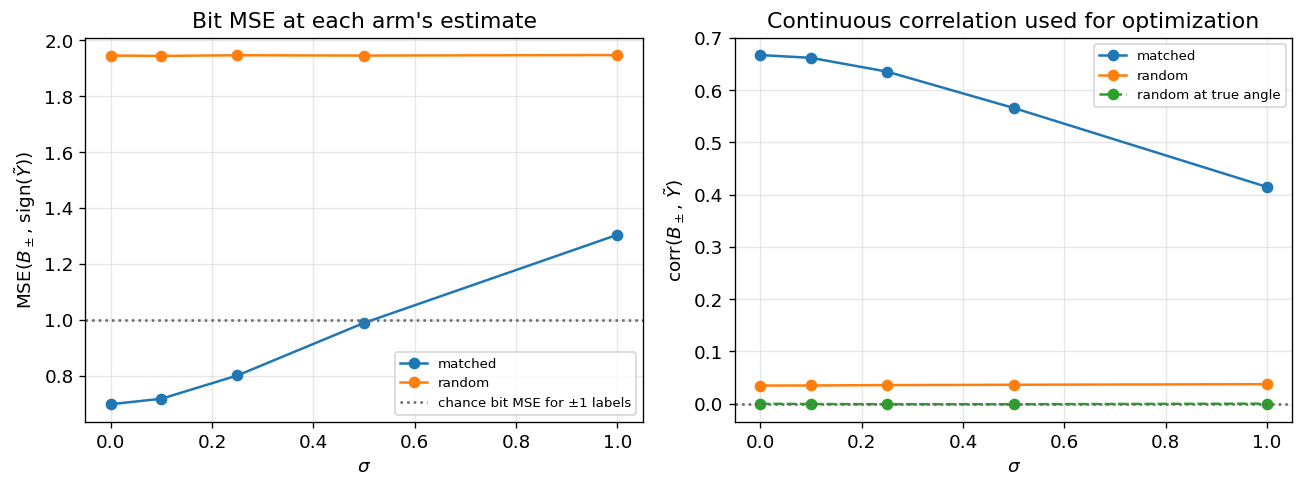

Fraction with |err| <= 2 deg:
           matched  random
noise_std                 
0.00           1.0    0.07
0.10           1.0    0.07
0.25           1.0    0.06
0.50           1.0    0.08
1.00           1.0    0.06


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(summary.noise_std, summary.matched_mean_bit_mse, "-o", label="matched")
axes[0].plot(summary.noise_std, summary.random_mean_bit_mse, "-o", label="random")
axes[0].axhline(1.0, color="0.4", ls=":", label="chance bit MSE for ±1 labels")
axes[0].set_xlabel(r"$\sigma$")
axes[0].set_ylabel(r"MSE($B_\pm$, sign($\tilde Y$))")
axes[0].set_title("Bit MSE at each arm's estimate")
axes[0].legend(fontsize=8)

axes[1].plot(summary.noise_std, summary.matched_mean_correlation, "-o", label="matched")
axes[1].plot(summary.noise_std, summary.random_mean_correlation, "-o", label="random")
axes[1].plot(summary.noise_std, summary.random_corr_at_true, "--o", label="random at true angle")
axes[1].axhline(0.0, color="0.4", ls=":")
axes[1].set_xlabel(r"$\sigma$")
axes[1].set_ylabel(r"corr($B_\pm$, $\tilde Y$)")
axes[1].set_title("Continuous correlation used for optimization")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "mse_and_correlation_vs_noise.png", bbox_inches="tight")
plt.show()

# How often does the random arm land near the true angle by chance?
near = results.assign(
    random_near_true=lambda frame: frame.random_angular_error <= 2.0,
    matched_near_true=lambda frame: frame.matched_angular_error <= 2.0,
)
print("Fraction with |err| <= 2 deg:")
print(
    near.groupby("noise_std")[["matched_near_true", "random_near_true"]]
    .mean()
    .rename(columns={"matched_near_true": "matched", "random_near_true": "random"})
    .round(3)
)


## 6. Outputs and reading the null check

If the matched arm recovers \(\theta\) and high bit accuracy while the random arm stays near chance bit accuracy and does not concentrate on \(\theta\), the sign-only template is carrying real geometric information. If the random arm also shows high bit accuracy after optimization, the procedure can invent correspondences.


In [9]:
metadata = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "n_trials": N_TRIALS,
    "noise_levels": NOISE_LEVELS,
    "angle_bounds_deg": list(ANGLE_BOUNDS),
    "template_access": "sign-only 0/1 bits from original image; exact zero -> 1",
    "observation_access": "full grayscale rotated image plus noise",
    "optimizer": "maximize corr(B_pm, R_{-phi}(Y)) with coarse grid + bounded Brent",
    "random_control": "independent sign field registered to the same observation",
    "valid_pixels": int(VALID_MASK.sum()),
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

print("Interpretation")
print(
    f"- Matched zero-noise mean |err|={zero.matched_mean_abs_err_deg:.4f} deg, "
    f"bit accuracy={zero.matched_mean_bit_accuracy:.4f}."
)
print(
    f"- Random zero-noise bit accuracy at its estimate={zero.random_mean_bit_accuracy:.4f}, "
    f"at true angle={zero.random_bit_accuracy_at_true:.4f}."
)
print(
    f"- At sigma={summary.noise_std.iloc[-1]:g}: matched bit accuracy="
    f"{summary.matched_mean_bit_accuracy.iloc[-1]:.3f}, random bit accuracy="
    f"{summary.random_mean_bit_accuracy.iloc[-1]:.3f}."
)
gap = summary.matched_mean_bit_accuracy - summary.random_mean_bit_accuracy
print(
    f"- Mean matched-minus-random bit-accuracy gap across noise levels: "
    f"{gap.mean():.3f} (min {gap.min():.3f}, max {gap.max():.3f})."
)
print(f"- Wrote {OUTPUT_DIR / 'metadata.json'}")


Interpretation
- Matched zero-noise mean |err|=0.0388 deg, bit accuracy=0.8255.
- Random zero-noise bit accuracy at its estimate=0.5136, at true angle=0.4997.
- At sigma=1: matched bit accuracy=0.674, random bit accuracy=0.513.
- Mean matched-minus-random bit-accuracy gap across noise levels: 0.261 (min 0.161, max 0.312).
- Wrote results\rotation_registration_sign_template\metadata.json
